# Nonlinear Response of the Vacuum Rabi Resonance for Photonic Qubit Modulation in CavityQED setup fundamentals for Bosonic Quantum Computing systems
Taken from publicly available source codes on QKD, QISKIT and Quantum devices and networking protocol developement




## Setup

In [ ]:
!pip install qutip

Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.2/16.2 MB 40.1 MB/s eta 0:00:00


In [ ]:
%matplotlib inline

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from qutip import *
from qutip.ui.progressbar import TextProgressBar as ProgressBar
qutip.settings.has_mkl = False

In [ ]:
# System parameters (in GHz)
omega_r = 6.92E9 * 2 * np.pi / 1E9        # Resonator frequency
omega_C1 = 400E6 * 2 * np.pi / 1E9        # Frequency associated with charging energy of qubit 1
omega_C2 = 340E6 * 2 * np.pi / 1E9        # Frequency associated with charging energy of qubit 2
omega_J = omega_r                         # Frequency associated with Josephson energy

g0_q1 = 347E6 * np.pi / 1E9               # Ground state coupling coefficient for qubit 1
g0_q2 = 94.4E6 * np.pi / 1E9              # Ground state coupling coefficient for qubit 2

swt_spot = 0
T_1_q1 = 1.4E-6 if swt_spot else 1.7E-6
T_2_q1 = 2.8E-6 if swt_spot else 0.7E-6
gamma_1 = 2 * np.pi / T_1_q1 / 1E9        # Rate of intrinsic relaxation of transmon excitations
gamma_phi = 0                             # Rate of pure dephasing of cavity photons (unused, ignored)
kappa = 300E3 * 2 * np.pi / 1E9           # Rate of loss of cavity photons

alpha = omega_C1                          # Anharmonicity of JC ladder (to first order)

In [ ]:
# Helper functions
def g_j(j):
    return g0_q1 * np.sqrt(j+1)
def alpha_j(j):
    return g_j(j) / g0_q1
def omega_j(j):
    return np.sqrt(8 * omega_C1 * omega_J) * (j + 1./2) - omega_C1 / 12 * (6*j**2 + 6*j + 3) - omega_J
def j_braket(j1,j2):
    if j1 >= N_atom or j2 >= N_atom:
        return tensor(qeye(N_light), identity(N_atom)-identity(N_atom))
    return tensor(qeye(N_light), fock(N_atom, j1) * fock(N_atom, j2).dag())

In [ ]:
# Simulation parameters
N_light = 7
N_atom = 2

# Supersplitting of the vacuum Rabi resonance when probing heterodyne transmission beyond linear response

In [ ]:
# Vary the driving force
xi_dbs = np.linspace(-70, -28, (70-28)*2+1)            # Driving strengths
omega_ds = np.linspace(7.08, 7.11, 200) * 2 * np.pi    # Driving frequencies

In [ ]:
# Find transmission amplitude for varying frequencies
results = []
pbar = ProgressBar(len(xi_dbs))
for i, xi_db in enumerate(xi_dbs):
    # Convert decibel to magnitude
    xi = 10**(xi_db/20)

    # Operators
    a = tensor(destroy(N_light), qeye(N_atom))
    sm = tensor(qeye(N_light), destroy(N_atom))
    
    # Solve master equation for different driving frequencies
    results.append([])
    for omega_d in omega_ds:
        # Hamiltonian
        H_res = (omega_r-omega_d) * a.dag() * a
        H_qub = (omega_r-omega_d) * sm.dag() * sm #sum([(omega_j(j)-omega_d) * j_braket(j,j) for j in range(N_atom)])
        H_int = g0_q1 * (a * sm.dag() + sm * a.dag()) #sum([g_j(j) * (a * j_braket(j+1,j) + j_braket(j,j+1) * a.dag()) for j in range(N_atom)])
        H_drv = xi * (a.dag() + a)
        H = H_res + H_qub + H_int + H_drv

        # Collapse operators
        damping = kappa * a
        relaxation = gamma_1 * sm #gamma_1 * sum([alpha_j(j) * j_braket(j,j+1) for j in range(N_atom-1)])
        c_ops = [damping, relaxation]
        
        # Steady-state solution of master equation
        rho_s = steadystate(H, c_ops)
        results[-1].append(np.abs(expect(a, rho_s))**2)
    
    # Update progress bar
    pbar.update(i)

10.6%. Run time:  29.52s. Est. time left: 00:00:04:09
20.0%. Run time:  39.61s. Est. time left: 00:00:02:38
30.6%. Run time:  50.37s. Est. time left: 00:00:01:54
40.0%. Run time:  60.04s. Est. time left: 00:00:01:30
50.6%. Run time:  69.62s. Est. time left: 00:00:01:07
60.0%. Run time:  79.12s. Est. time left: 00:00:00:52
70.6%. Run time:  89.65s. Est. time left: 00:00:00:37
80.0%. Run time:  99.10s. Est. time left: 00:00:00:24
90.6%. Run time: 110.16s. Est. time left: 00:00:00:11


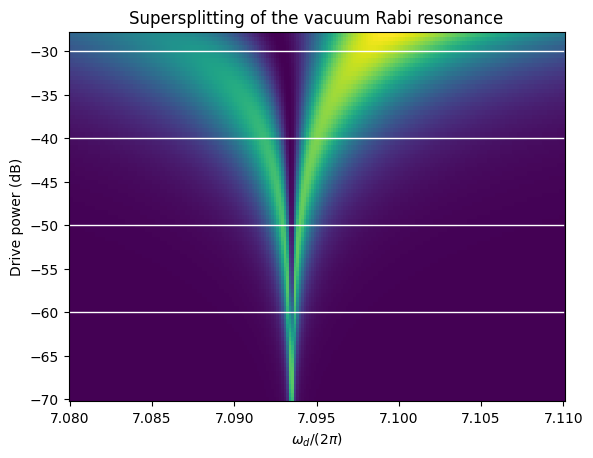

In [ ]:
# Generate pseudocolor plot of transmission amplitude response over parameter space
plt.title('Supersplitting of the vacuum Rabi resonance')
plt.xlabel('$\omega_d / (2 \pi)$')
plt.ylabel('Drive power (dB)')
for i in range(-30, -70, -10):
    plt.plot(omega_ds/(2*np.pi),[i]*len(omega_ds), 'w', linewidth=1)
plt.pcolor(omega_ds/(2*np.pi), xi_dbs, results)
plt.show()

-60.5 dB


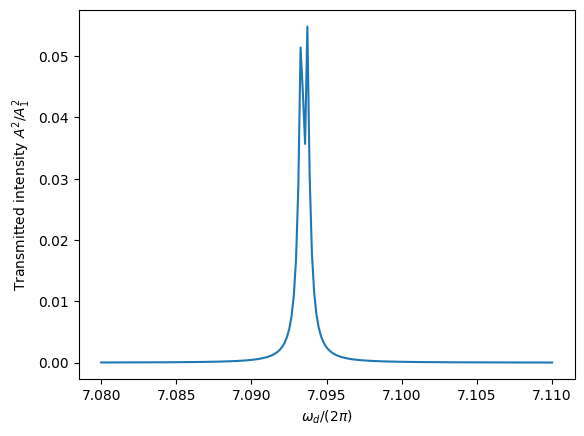

-60.0 dB


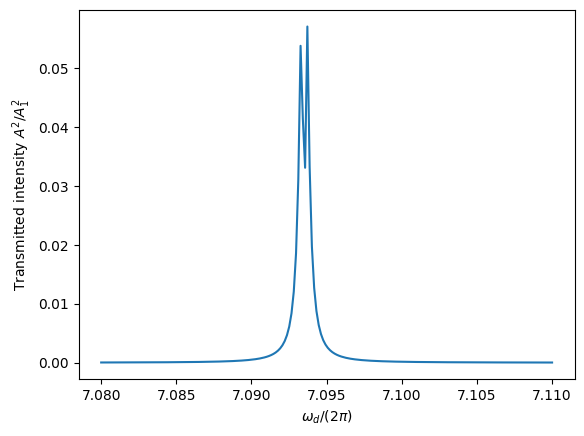

-50.5 dB


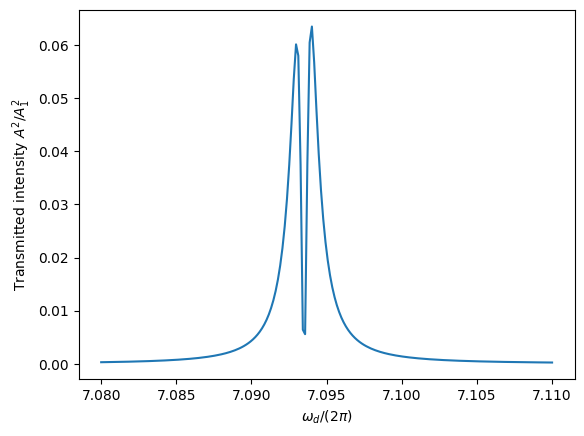

-50.0 dB


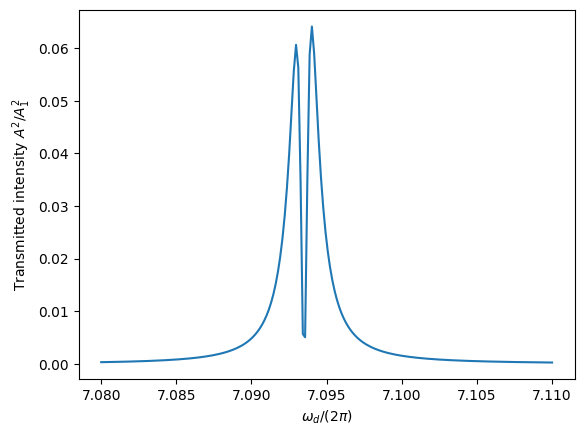

-40.5 dB


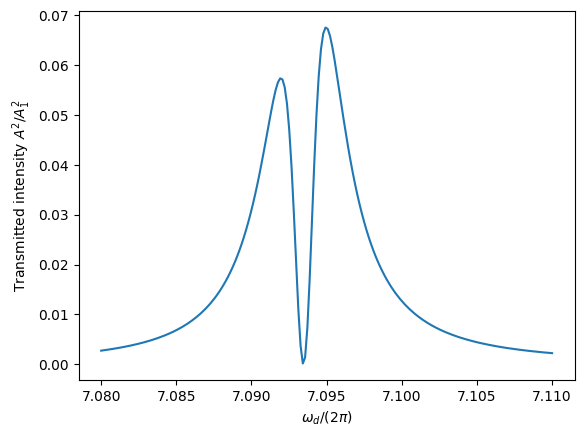

-40.0 dB


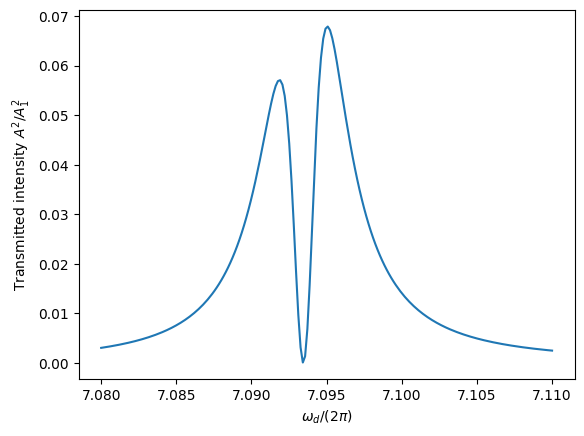

-30.5 dB


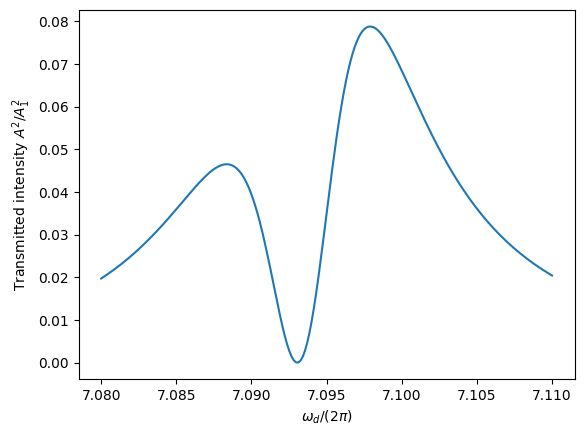

-30.0 dB


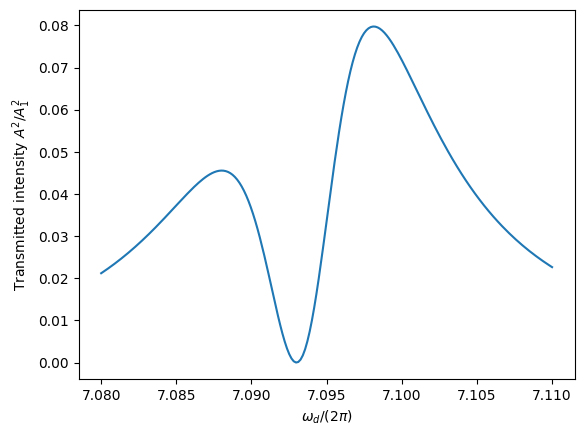

In [ ]:
# Plot selected cuts
for i, xi_db in enumerate(xi_dbs):
    if int(xi_db) in range(-30, -70, -10):
        print(xi_db, "dB")
        plt.xlabel('$\omega_d / (2 \pi)$')
        plt.ylabel('Transmitted intensity $A^2 / A^2_1$')
        try:
            plt.plot(omega_ds/(2*np.pi), results[i])
        except IndexError:
            plt.plot(omega_ds/(2*np.pi), results[-1])
        plt.show()

## Figure 3: Emergence of sqrt(n) peaks under strong driving of the vacuum Rabi transition

In [ ]:
# Vary the driving force
xi_dbs = np.linspace(-50, -15, (50-15)*2+1)                     # Driving strengths
omega_ds = np.linspace(6.65, 7.2, 200) * 2 * np.pi        # Driving frequencies

In [ ]:
# Find transmission amplitude for varying frequencies
results = []
pbar = ProgressBar(len(xi_dbs))
for i, xi_db in enumerate(xi_dbs):
    # Convert decibel to magnitude
    xi = 10**(xi_db/20)

    # Operators
    a = tensor(destroy(N_light), qeye(N_atom))
    sm = tensor(qeye(N_light), destroy(N_atom))
    
    # Solve master equation for different driving frequencies
    results.append([])
    for omega_d in omega_ds:
        # Hamiltonian
        H_res = (omega_r-omega_d) * a.dag() * a
        H_qub = (omega_r-omega_d) * sm.dag() * sm #sum([(omega_j(j)-omega_d) * j_braket(j,j) for j in range(N_atom)])
        H_int = g0_q1 * (a * sm.dag() + sm * a.dag()) #sum([g_j(j) * (a * j_braket(j+1,j) + j_braket(j,j+1) * a.dag()) for j in range(N_atom)])
        H_drv = xi * (a.dag() + a)
        H = H_res + H_qub + H_int + H_drv

        # Collapse operators
        damping = kappa * a
        relaxation = gamma_1 * sm #gamma_1 * sum([alpha_j(j) * j_braket(j,j+1) for j in range(N_atom-1)])
        c_ops = [damping, relaxation]
        
        # Steady-state solution of master equation
        rho_s = steadystate(H, c_ops)
        results[-1].append(np.abs(expect(a, rho_s))**2)
    
    # Update progress bar
    pbar.update(i)

11.3%. Run time:  12.02s. Est. time left: 00:00:01:34
21.1%. Run time:  20.70s. Est. time left: 00:00:01:17
31.0%. Run time:  28.98s. Est. time left: 00:00:01:04
40.8%. Run time:  36.95s. Est. time left: 00:00:00:53
50.7%. Run time:  45.58s. Est. time left: 00:00:00:44
60.6%. Run time:  53.07s. Est. time left: 00:00:00:34
70.4%. Run time:  61.62s. Est. time left: 00:00:00:25
80.3%. Run time:  70.10s. Est. time left: 00:00:00:17
90.1%. Run time:  77.55s. Est. time left: 00:00:00:08


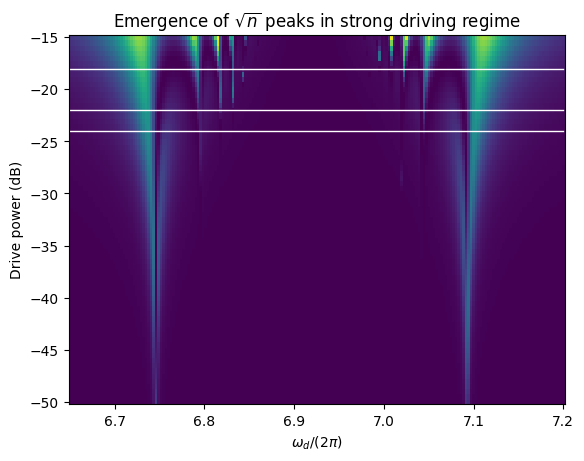

In [ ]:
# Generate pseudocolor plot of transmission amplitude response over parameter space
plt.title('Emergence of $\sqrt{n}$ peaks in strong driving regime')
plt.xlabel('$\omega_d / (2 \pi)$')
plt.ylabel('Drive power (dB)')
plt.plot(omega_ds/(2*np.pi),[-24]*len(omega_ds), 'w', linewidth=1)
plt.plot(omega_ds/(2*np.pi),[-22]*len(omega_ds), 'w', linewidth=1)
plt.plot(omega_ds/(2*np.pi),[-18]*len(omega_ds), 'w', linewidth=1)
plt.pcolor(omega_ds/(2*np.pi), xi_dbs, results)
plt.show()

-24.5 dB


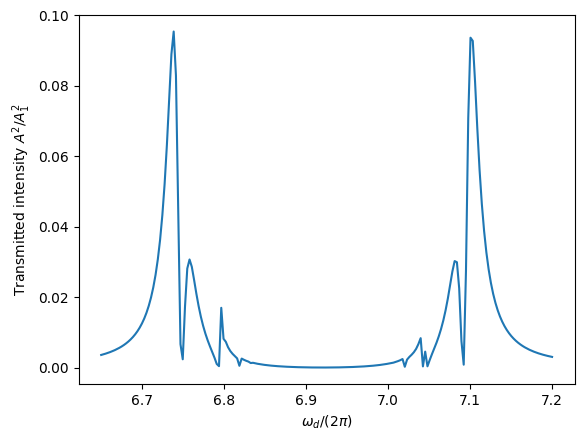

-24.0 dB


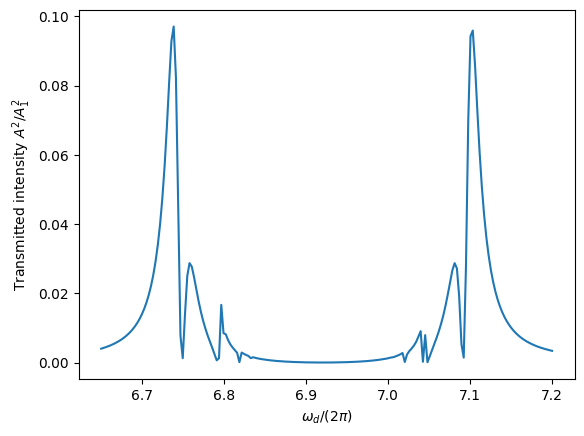

-22.5 dB


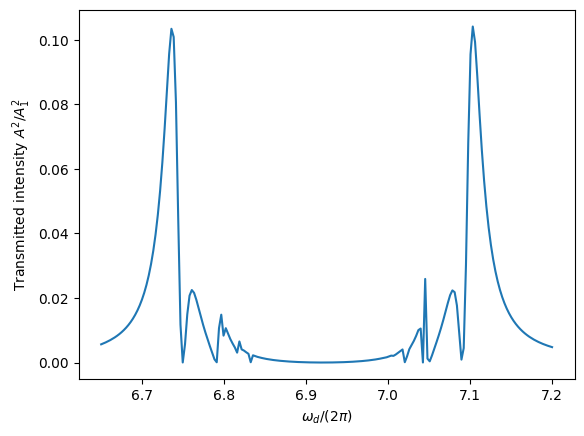

-22.0 dB


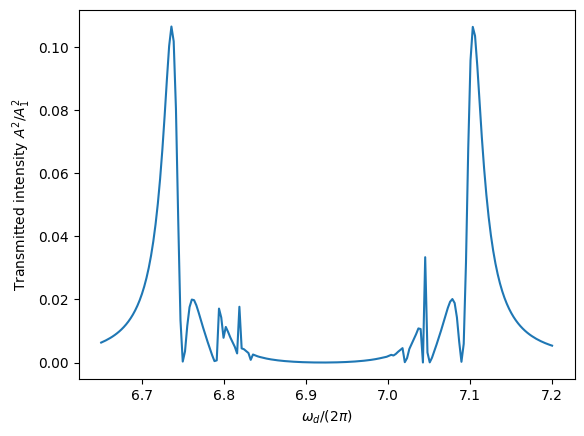

-18.5 dB


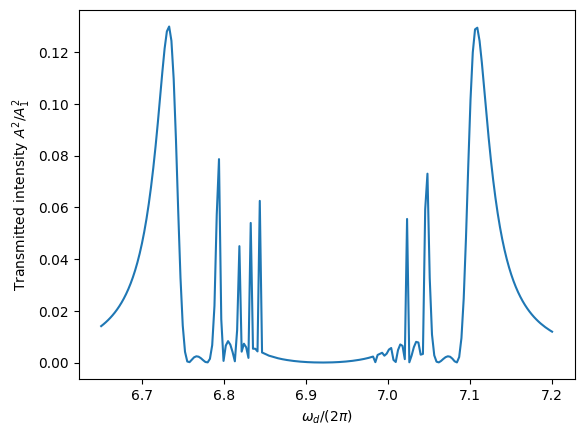

-18.0 dB


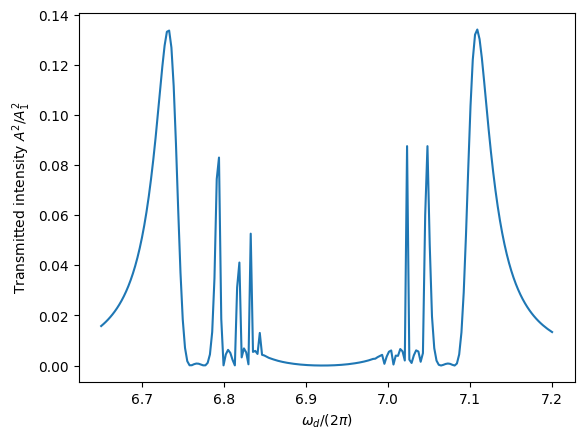

In [ ]:
# Plot selected cuts
for i, xi_db in enumerate(xi_dbs):
    if int(xi_db) in [-24, -22, -18]:
        print (xi_db, "dB")
        plt.xlabel('$\omega_d / (2 \pi)$')
        plt.ylabel('Transmitted intensity $A^2 / A^2_1$')
        plt.plot(omega_ds/(2*np.pi), results[i])
        plt.show()

## Figure 4: Qubit–cavity avoided crossing at high drive power

In [ ]:
# Vary the magnetic field (which varies the qubit frequency)
Bs = np.linspace(2.53, 2.56, 81)         # Qubit frequencies
omega_ds = np.linspace(6.85, 7, 200) * 2 * np.pi    # Driving frequencies

In [ ]:
# Find transmission amplitude for varying frequencies
results = []
pbar = ProgressBar(len(Bs))
for i, B in enumerate(Bs):
    # Convert decibel to magnitude
    xi = 10**(-8/20)
    
    omega_j = 1.1 * omega_r * np.sqrt(np.abs(np.cos(B)))

    # Operators
    a = tensor(destroy(N_light), qeye(N_atom))
    sm = tensor(qeye(N_light), destroy(N_atom))
    
    # Solve master equation for different driving frequencies
    results.append([])
    for omega_d in omega_ds:
        # Hamiltonian
        H_res = (omega_r-omega_d) * a.dag() * a
        H_qub = (omega_r-omega_j) * sm.dag() * sm #sum([(omega_j(j)-omega_d) * j_braket(j,j) for j in range(N_atom)])
        H_int = g0_q2 * (a * sm.dag() + sm * a.dag()) #sum([g_j(j) * (a * j_braket(j+1,j) + j_braket(j,j+1) * a.dag()) for j in range(N_atom)])
        H_drv = xi * (a.dag() + a)
        H = H_res + H_qub + H_int + H_drv

        # Collapse operators
        damping = kappa * a
        relaxation = gamma_1 * sm #gamma_1 * sum([alpha_j(j) * j_braket(j,j+1) for j in range(N_atom-1)])
        c_ops = [damping, relaxation]
        
        # Steady-state solution of master equation
        rho_s = steadystate(H, c_ops)
        results[-1].append(np.abs(expect(a, rho_s))**2)
    
    # Update progress bar
    pbar.update(i)

11.1%. Run time:  12.00s. Est. time left: 00:00:01:36
21.0%. Run time:  21.85s. Est. time left: 00:00:01:22
30.9%. Run time:  31.51s. Est. time left: 00:00:01:10
40.7%. Run time:  40.78s. Est. time left: 00:00:00:59
50.6%. Run time:  49.82s. Est. time left: 00:00:00:48
60.5%. Run time:  59.46s. Est. time left: 00:00:00:38
70.4%. Run time:  69.10s. Est. time left: 00:00:00:29
80.2%. Run time:  77.81s. Est. time left: 00:00:00:19
90.1%. Run time:  87.71s. Est. time left: 00:00:00:09


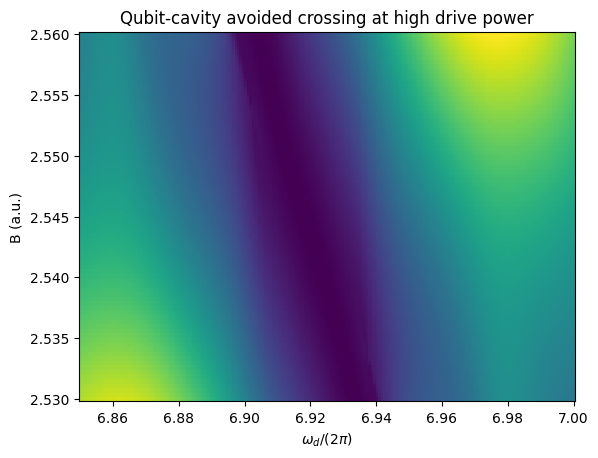

In [ ]:
# Generate pseudocolor plot of transmission amplitude response over parameter space
plt.title('Qubit-cavity avoided crossing at high drive power')
plt.xlabel('$\omega_d / (2 \pi)$')
plt.ylabel('B (a.u.)')
plt.pcolor(omega_ds/(2*np.pi), Bs, results)
plt.show()

## Versions

In [ ]:
from qutip.ipynbtools import version_table

version_table()

Software,Version
QuTiP,4.7.1
Numpy,1.22.4
SciPy,1.10.1
matplotlib,3.7.1
Cython,0.29.34
Number of CPUs,2
BLAS Info,OPENBLAS
IPython,7.34.0
Python,"3.10.11 (main, Apr 5 2023, 14:15:10) [GCC 9.4.0]"
OS,posix [linux]
